# EDA

In [ ]:
import warnings
warnings.filterwarnings("ignore")
import pydicom
from glob import glob
import pandas as pd 
import re
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
df = pd.read_csv('/kaggle/input/datasets/malihealavi/knee-abnormally-dataset/labeld_df.csv')
(df.head(2))
df.columns

Index(['StudyInstanceUID', 'Report', 'ACL', 'MCL', 'Medial Meniscus',
       'Lateral Meniscus', 'Medial OA', 'Lateral OA', 'PF OA', 'Effusion',
       'Synovitis', 'Baker's', 'Contusion', 'Fracture'],
      dtype='object')

In [ ]:
df_merged = pd.read_csv('/kaggle/input/datasets/malihealavi/knee-abnormally-dataset/df_merged.csv')
(df_merged.head(2))

,StudyInstanceUID,SeriesInstanceUID,Fluid_Sensitive,Fat_Suppression,Anatomical_Plane,file_path,InstanceNumber,SeriesDescription,BodyPartExamined,Laterality,PatientSex,ScanningSequence,SequenceVariant,ScanOptions,MRAcquisitionType,Rows,Columns,MagneticFieldStrength,FlipAngle,Manufacturer
0,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.12343110195036213483...,1,1,Sagittal,['/kaggle/input/competitions/rsna-knee-abnorma...,22,DP SPIR CS_SAG,KNEE,NaN,F,SE,SK,FS,2D,512,512,1.5,90.0,Philips
1,1.2.826.0.1.3680043.8.498.10004873229099053869...,1.2.826.0.1.3680043.8.498.13821229744997220641...,1,1,Axial,['/kaggle/input/competitions/rsna-knee-abnorma...,18,STIR CS_ AX,KNEE,NaN,F,IR,SK,OTHER,2D,560,560,1.5,90.0,Philips


In [ ]:
df_merged.columns

Index(['StudyInstanceUID', 'SeriesInstanceUID', 'Fluid_Sensitive',
       'Fat_Suppression', 'Anatomical_Plane', 'file_path', 'InstanceNumber',
       'SeriesDescription', 'BodyPartExamined', 'Laterality', 'PatientSex',
       'ScanningSequence', 'SequenceVariant', 'ScanOptions',
       'MRAcquisitionType', 'Rows', 'Columns', 'MagneticFieldStrength',
       'FlipAngle', 'Manufacturer'],
      dtype='object')

In [ ]:
cols = ['BodyPartExamined',
'Laterality',
'PatientSex',
'ScanningSequence',
'SequenceVariant',
# 'ScanOptions',
'MRAcquisitionType',
'MagneticFieldStrength',
'FlipAngle',
'Manufacturer']
for col in cols:
    print(f'{col} : {df_merged[col].unique()}')

BodyPartExamined : ['KNEE' 'EXTREMITY' 'PATELLA' nan 'WRIST' 'SHOULDER' 'BRAIN' 'LIVER'
 'ANKLE' 'ADRENAL' 'HEAD' 'ELBOW' 'ABDOMEN' 'ILEUM' 'HEART' 'CAROTID'
 'CSPINE' 'BRONCHUS' 'LSSPINE' 'KIDNEY' 'ESOPHAGUS' 'SPINE' 'LSPINE']
Laterality : [nan 'RIGHT' 'LEFT' 'B']
PatientSex : ['F' 'M' nan 'O']
ScanningSequence : ['SE' 'IR' 'GR' nan 'RM' "['SE', 'IR']" "['IR', 'SE']"]
SequenceVariant : ['SK' "['SP', 'SK']" "['SK', 'SP', 'OSP']" "['SP', 'OSP']" "['SK', 'OSP']"
 nan "['SK', 'SP']" 'SP' "['SS', 'SK']" 'NONE' 'OSP' "['OSP', 'WI']"
 "['IR', 'OSP']" 'SS' "['SS', 'OSP']" "['SK', 'SP', 'MP', 'OSP']"
 "['SS', 'SK', 'OSP']"]
MRAcquisitionType : ['2D' '3D' nan]
MagneticFieldStrength : [1.5  3.    nan 1.16 1.  ]
FlipAngle : [ 90. 180. 150. 131. 134.  10. 160. 100.  nan 170. 120.  30. 122.  25.
 142.   5.   1. 111. 138.  35.  15. 176. 140. 141. 125. 152. 167. 114.
 112. 124. 130. 143. 149. 175. 163.  27. 159. 166. 165.  20. 128.  57.
 132. 144. 133. 168. 164. 179. 178. 162.  71. 177. 137. 145. 147

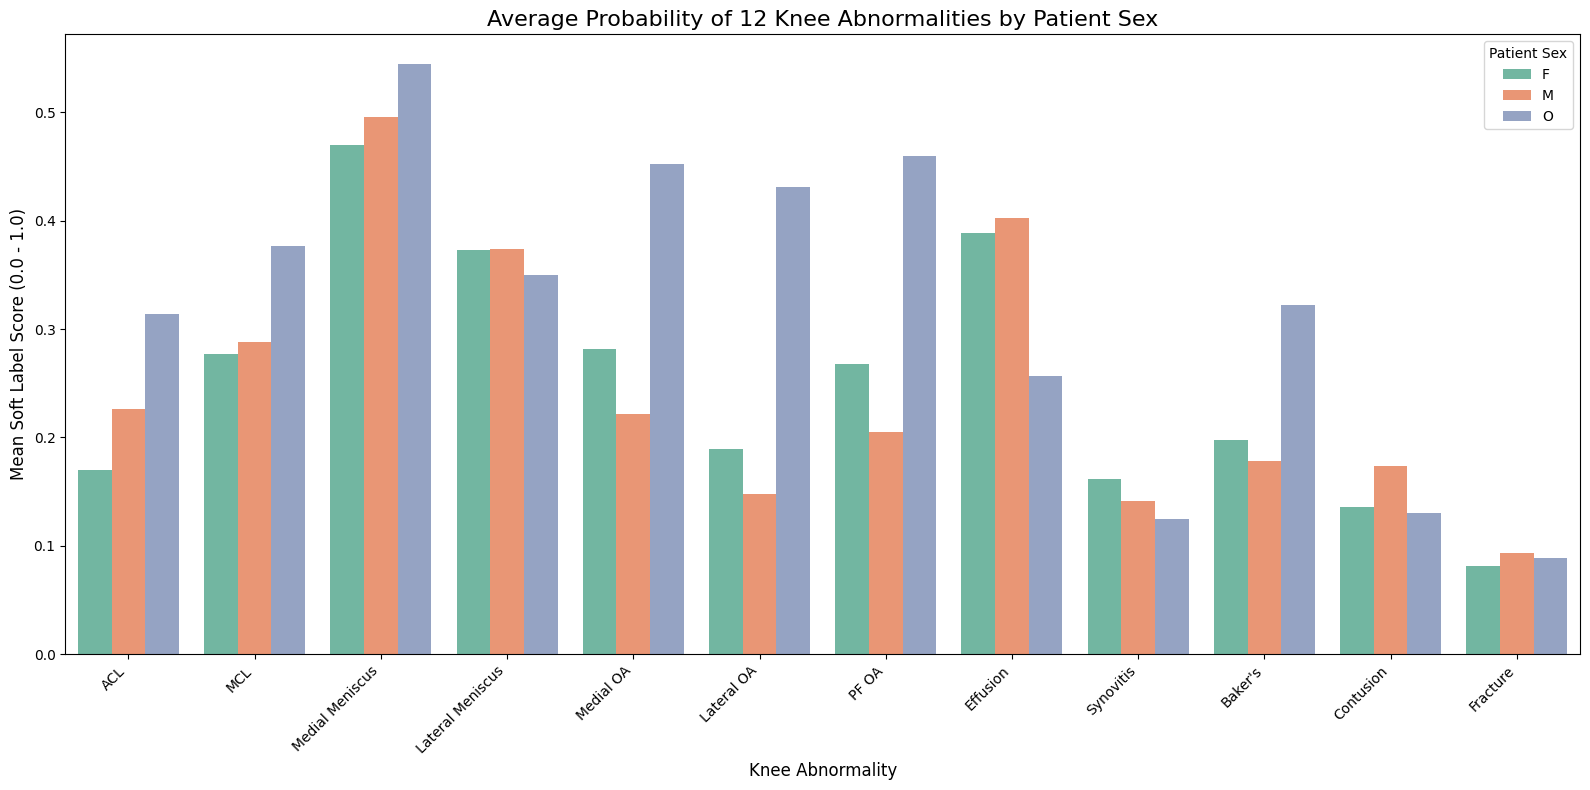

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


series_df = df_merged
study_df = df
# 1. Extract and deduplicate patient sex per study
patient_sex_df = series_df[['StudyInstanceUID', 'PatientSex']].drop_duplicates()

# 2. Merge demographics with the study labels
merged_df = pd.merge(study_df, patient_sex_df, on='StudyInstanceUID', how='inner')

# 3. Define the 12 target abnormality labels
target_labels = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 
    'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

# 4. Melt the dataframe into a long format for Seaborn plotting
melted_df = merged_df.melt(
    id_vars=['StudyInstanceUID', 'PatientSex'], 
    value_vars=target_labels, 
    var_name='Condition', 
    value_name='Probability'
)

# 5. Plot the average probability of each condition grouped by sex
plt.figure(figsize=(16, 8))
sns.barplot(
    data=melted_df, 
    x='Condition', 
    y='Probability', 
    hue='PatientSex', 
    palette='Set2',
    errorbar=None # Hides error bars for a cleaner look; remove to see variance
)

plt.title('Average Probability of 12 Knee Abnormalities by Patient Sex', fontsize=16)
plt.xlabel('Knee Abnormality', fontsize=12)
plt.ylabel('Mean Soft Label Score (0.0 - 1.0)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Patient Sex')
plt.tight_layout()
plt.show()

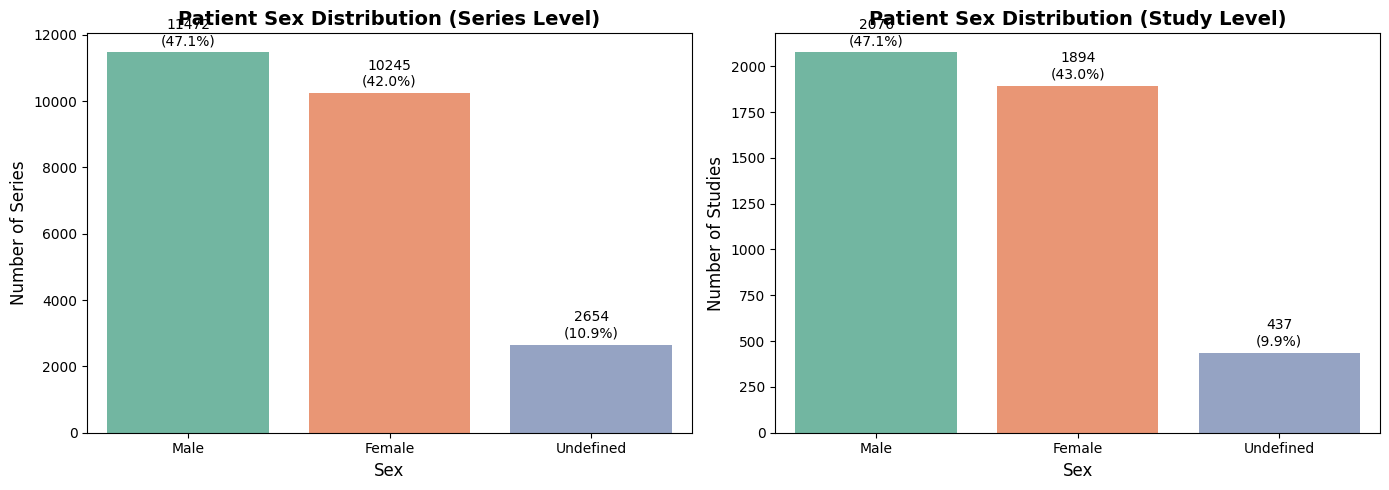

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map 'M', 'F' and handle missing/empty values as 'Undefined'
def categorize_sex(val):
    if pd.isna(val) or str(val).strip() not in ['M', 'F']:
        return 'Undefined'
    return 'Male' if val == 'M' else 'Female'

series_df['Sex_Category'] = series_df['PatientSex'].apply(categorize_sex)

# 2. Compute Series-level counts and percentages
series_counts = series_df['Sex_Category'].value_counts()
series_pct = series_df['Sex_Category'].value_counts(normalize=True) * 100

# 3. Compute Study-level counts and percentages (deduplicated by study)
study_sex_df = series_df[['StudyInstanceUID', 'Sex_Category']].drop_duplicates()
study_counts = study_sex_df['Sex_Category'].value_counts()
study_pct = study_sex_df['Sex_Category'].value_counts(normalize=True) * 100

# 4. Display combined summary DataFrame
summary_df = pd.DataFrame({
    'Series Count': series_counts,
    'Series (%)': series_pct.round(2),
    'Study Count': study_counts,
    'Study (%)': study_pct.round(2)
}).fillna(0)

# 5. Visualizations: Side-by-Side Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Series-Level Chart
sns.barplot(x=series_counts.index, y=series_counts.values, ax=axes[0], palette='Set2')
axes[0].set_title('Patient Sex Distribution (Series Level)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Sex', fontsize=12)
axes[0].set_ylabel('Number of Series', fontsize=12)
for p in axes[0].patches:
    val = int(p.get_height())
    pct = (val / len(series_df)) * 100
    axes[0].annotate(f'{val}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., val),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

# Study-Level Chart
sns.barplot(x=study_counts.index, y=study_counts.values, ax=axes[1], palette='Set2')
axes[1].set_title('Patient Sex Distribution (Study Level)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Sex', fontsize=12)
axes[1].set_ylabel('Number of Studies', fontsize=12)
for p in axes[1].patches:
    val = int(p.get_height())
    pct = (val / len(study_sex_df)) * 100
    axes[1].annotate(f'{val}\n({pct:.1f}%)', (p.get_x() + p.get_width() / 2., val),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

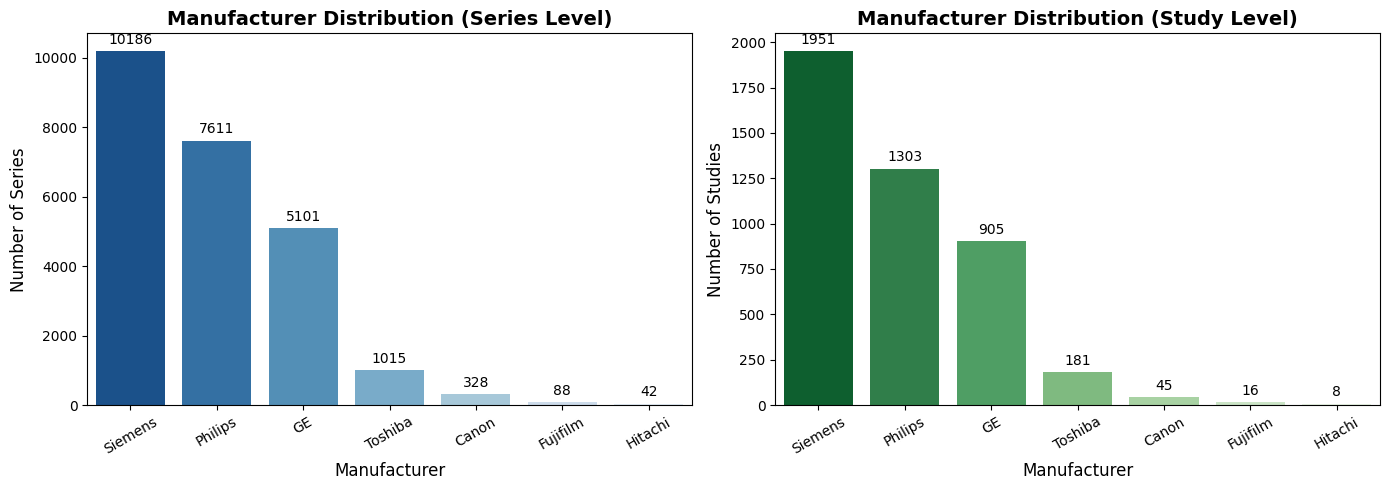

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Clean missing values if any
series_df['Manufacturer'] = series_df['Manufacturer'].fillna('Unknown')

# 2. Calculate Series-level manufacturer counts
series_mfg_counts = series_df['Manufacturer'].value_counts()

# 3. Calculate Study-level manufacturer counts (deduplicate by study and manufacturer)
study_mfg_df = series_df[['StudyInstanceUID', 'Manufacturer']].drop_duplicates()
study_mfg_counts = study_mfg_df['Manufacturer'].value_counts()

# 4. Plot both distributions side-by-side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Series-Level Plot
sns.barplot(x=series_mfg_counts.index, y=series_mfg_counts.values, ax=axes[0], palette='Blues_r')
axes[0].set_title('Manufacturer Distribution (Series Level)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Manufacturer', fontsize=12)
axes[0].set_ylabel('Number of Series', fontsize=12)
axes[0].tick_params(axis='x', rotation=30)
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

# Study-Level Plot
sns.barplot(x=study_mfg_counts.index, y=study_mfg_counts.values, ax=axes[1], palette='Greens_r')
axes[1].set_title('Manufacturer Distribution (Study Level)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Manufacturer', fontsize=12)
axes[1].set_ylabel('Number of Studies', fontsize=12)
axes[1].tick_params(axis='x', rotation=30)
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', xytext=(0, 3), textcoords='offset points')

plt.tight_layout()
plt.show()

--- Soft Target Summary Statistics ---
                   Mean    Std  Median (50%)  Min  Max
ACL               0.215  0.305           0.1  0.0  1.0
MCL               0.298  0.355           0.1  0.0  1.0
Medial Meniscus   0.485  0.365           0.5  0.0  1.0
Lateral Meniscus  0.371  0.377           0.1  0.0  1.0
Medial OA         0.269  0.349           0.1  0.0  1.0
Lateral OA        0.186  0.297           0.1  0.0  1.0
PF OA             0.253  0.343           0.1  0.0  1.0
Effusion          0.401  0.337           0.3  0.0  1.0
Synovitis         0.171  0.263           0.1  0.0  1.0
Baker's           0.198  0.297           0.1  0.0  1.0
Contusion         0.159  0.244           0.1  0.0  1.0
Fracture          0.090  0.202           0.0  0.0  1.0

--- Value Counts per Soft Target Level ---
                   0.0   0.1  0.2  0.3  0.4  0.5  0.6   0.7  0.8  0.9  1.0
ACL               1052  2430   10  124    0    0    1   372    4  115  299
MCL               1319  1441   12  338   11   15    

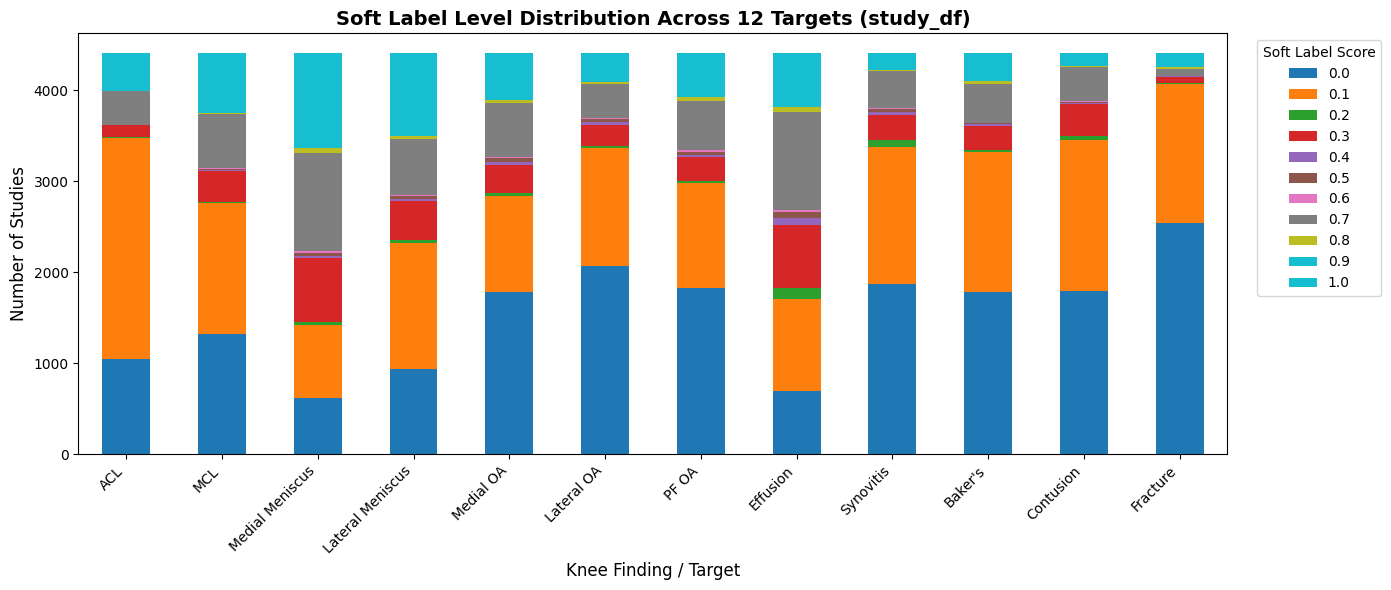

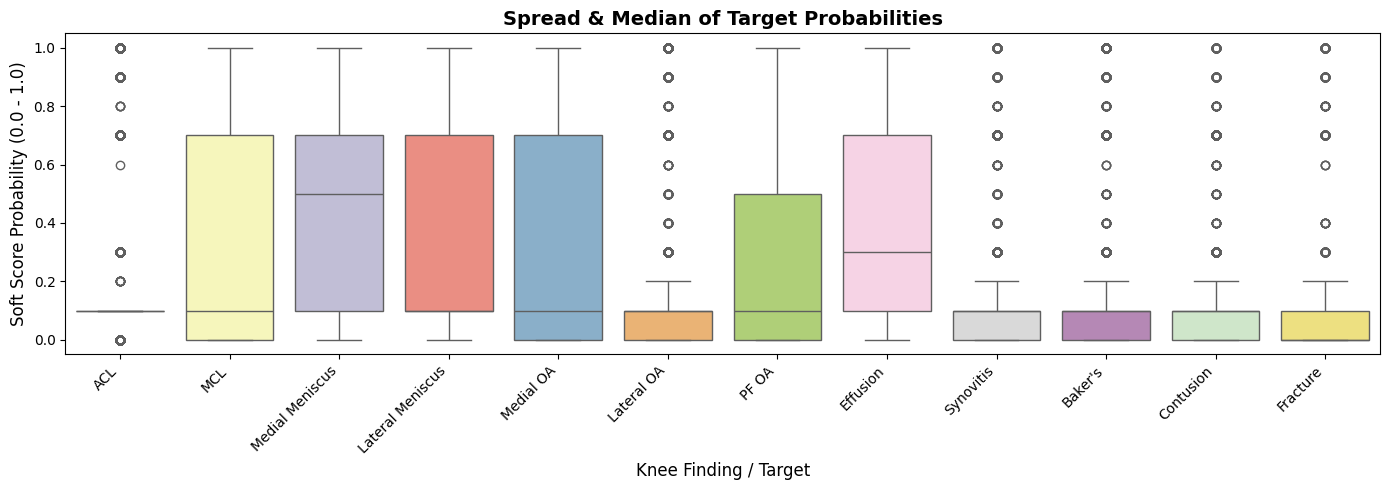

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

target_cols = [
    'ACL', 'MCL', 'Medial Meniscus', 'Lateral Meniscus', 'Medial OA', 
    'Lateral OA', 'PF OA', 'Effusion', 'Synovitis', "Baker's", 'Contusion', 'Fracture'
]

# 1. Continuous Summary Statistics (Mean, Median, Std, Min, Max)
summary_stats = study_df[target_cols].describe().T[['mean', 'std', '50%', 'min', 'max']]
summary_stats.columns = ['Mean', 'Std', 'Median (50%)', 'Min', 'Max']
print("--- Soft Target Summary Statistics ---")
print(summary_stats.round(3))

# 2. Discrete Soft Label Frequency Counts
# Rounding handles float precision issues when grouping standard soft levels (0.0, 0.1, 0.25, 0.5, 0.75, 1.0)
df_rounded = study_df[target_cols].round(2)
label_counts = df_rounded.apply(pd.Series.value_counts).fillna(0).T

print("\n--- Value Counts per Soft Target Level ---")
print(label_counts.astype(int))

# 3. Visualization 1: Stacked Bar Chart of Discrete Soft Levels per Target
fig, ax = plt.subplots(figsize=(14, 6))
label_counts.plot(kind='bar', stacked=True, colormap='tab10', ax=ax)

plt.title('Soft Label Level Distribution Across 12 Targets (study_df)', fontsize=14, fontweight='bold')
plt.xlabel('Knee Finding / Target', fontsize=12)
plt.ylabel('Number of Studies', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(title='Soft Label Score', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. Visualization 2: Boxplot showing Continuous Score Spread & Outliers
plt.figure(figsize=(14, 5))
sns.boxplot(data=study_df[target_cols], palette='Set3')

plt.title('Spread & Median of Target Probabilities', fontsize=14, fontweight='bold')
plt.xlabel('Knee Finding / Target', fontsize=12)
plt.ylabel('Soft Score Probability (0.0 - 1.0)', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

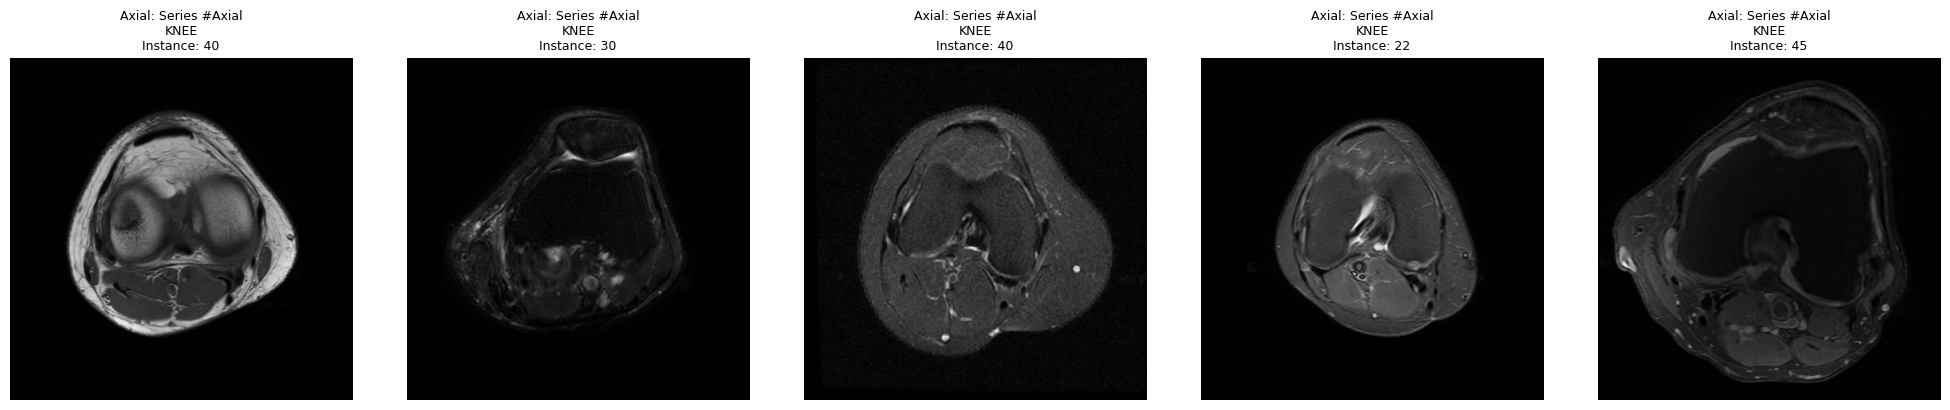

In [ ]:


import ast
import numpy as np
import matplotlib.pyplot as plt
import pydicom
def plot_dicom_samples(samples_df, title_prefix=""):
    """Plots up to 5 DICOM images side-by-side from a sampled dataframe."""
    fig, axes = plt.subplots(1, 5, figsize=(20, 4))  # Adjusted height from 16 to 4 for a single row
    axes = axes.flatten()

    for i, (ax, (_, row)) in enumerate(zip(axes, samples_df.iterrows())):
        # Read the file path using your middle-slice logic
        file_list = ast.literal_eval(row["file_path"])
        middle_idx = int(np.ceil(row["InstanceNumber"] / 2))
        
        # Prevent index out of bounds if InstanceNumber doesn't match list length
        idx = min(middle_idx, len(file_list) - 1) 
        
        ds = pydicom.dcmread(file_list[idx])
        image = ds.pixel_array

        # Display image
        ax.imshow(image, cmap="gray")
        ax.axis("off")

        # Set labels
        ax.set_title(
            f"{title_prefix} Series #{row['Anatomical_Plane']}\n"
            f"{row['BodyPartExamined']}\n"
            f"Instance: {row['InstanceNumber']}",
            fontsize=9
        )

    # Hide unused axes if there are fewer than 5 samples
    for ax in axes[len(samples_df):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

df = df_merged

# FIX: Use '==' to correctly filter each anatomical plane
axial    = df[df['Anatomical_Plane'] == 'Axial']
sagittal = df[df['Anatomical_Plane'] == 'Sagittal']
coronal  = df[df['Anatomical_Plane'] == 'Coronal']

# Sampling code remains the same
num_series = df["SeriesInstanceUID"].nunique()

axial_samples = (
    axial.groupby("SeriesInstanceUID", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=min(5, num_series), random_state=42, replace=True if len(axial) < 5 else False)
)
sagittal_samples = (
    sagittal.groupby("SeriesInstanceUID", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=min(5, num_series), random_state=42, replace=True if len(sagittal) < 5 else False)
)
coronal_samples = (
    coronal.groupby("SeriesInstanceUID", group_keys=False)
    .sample(n=1, random_state=42)
    .sample(n=min(5, num_series), random_state=42, replace=True if len(coronal) < 5 else False)
)
# Plot Axial Slices
plot_dicom_samples(axial_samples, title_prefix="Axial:")

# Plot Sagittal Slices
plot_dicom_samples(sagittal_samples, title_prefix="Sagittal:")

# Plot Coronal Slices
plot_dicom_samples(coronal_samples, title_prefix="Coronal:")


In [ ]:
TRAIN_SERIES_PATH = '/kaggle/input/competitions/rsna-knee-abnormality-detection/train_series'
TEST_SERIES_PATH = '/kaggle/input/competitions/rsna-knee-abnormality-detection/test_series'


In [ ]:

def load_dicom_image(path, img_size, voi_lut=True, rotate=0):
    dicom = pydicom.dcmread(path)
    if voi_lut:
        try:
            data = apply_voi_lut(dicom.pixel_array, dicom)
        except Exception:
            data = dicom.pixel_array
    else:
        data = dicom.pixel_array
        
    data = data.astype(np.float32)
    return data


def load_dicom_images_3d(StudyInstanceUID,SeriesInstanceUID, num_imgs, img_size, split="train", rotate=0, data_directory="."):
    if split == 'train':
        path_pattern = f"{TRAIN_SERIES_PATH}/{StudyInstanceUID}/{SeriesInstanceUID}/*.dcm"
    elif split == 'test':
        path_pattern = f"{TEST_SERIES_PATH}/{StudyInstanceUID}/{SeriesInstanceUID}/*.dcm"
        
    files = sorted(glob(path_pattern), 
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])
    
    if len(files) == 0:
        return np.zeros(( num_imgs, img_size, img_size), dtype=np.float32)
    
    middle = len(files) // 2
    num_imgs2 = num_imgs // 2
    # plt.imshow(load_dicom_image(files[middle], img_size=256, rotate=0) , cmap='gray')   
    p1 = max(0, middle - num_imgs2)
    p2 = min(len(files), middle + num_imgs2)
    
    img3d = np.stack([load_dicom_image(f, img_size=img_size, rotate=rotate, voi_lut=True) for f in files[p1:p2]], axis=0) 
    # ----------- img3d = num_slices * H*W
    # return img3d  
    return img3d


(22, 512, 512) 1054.0 0.0


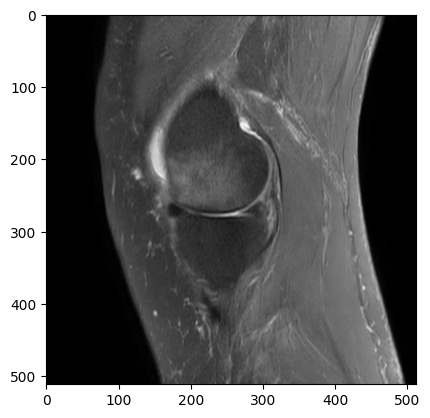

In [ ]:
seriesUID = '1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772'
studtUID = '1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260'
sample = load_dicom_images_3d(studtUID, seriesUID , 32, 512,  split="train", rotate=0, )
print(sample.shape, np.max(sample) , np.min(sample))
plt.imshow(sample[12], cmap='gray')

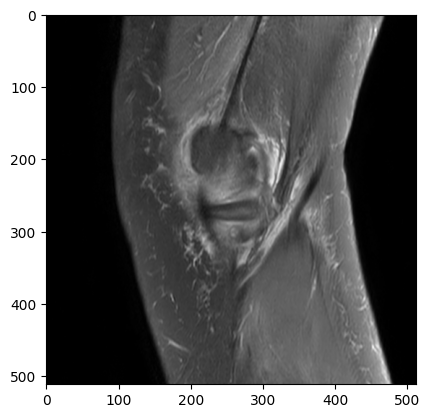

In [ ]:
plt.imshow(sample[21], cmap='gray')

In [ ]:
import ipywidgets as widgets
from IPython.display import display
import matplotlib.pyplot as plt
from glob import glob
import re

def load_full_series(StudyInstanceUID, SeriesInstanceUID, img_size, split="train"):
    if split == 'train':
        path_pattern = f"{TRAIN_SERIES_PATH}/{StudyInstanceUID}/{SeriesInstanceUID}/*.dcm"
    else:
        path_pattern = f"{TEST_SERIES_PATH}/{StudyInstanceUID}/{SeriesInstanceUID}/*.dcm"

    files = sorted(glob(path_pattern),
                   key=lambda var: [int(x) if x.isdigit() else x for x in re.findall(r'[^0-9]|[0-9]+', var)])

    img3d = np.stack([load_dicom_image(f, img_size=img_size, voi_lut=True) for f in files], axis=0)
    return img3d

seriesUID = '1.2.826.0.1.3680043.8.498.12343110195036213483454091715412333772'
studtUID = '1.2.826.0.1.3680043.8.498.10004873229099053869093324292195817260'
# Load ALL frames in the series (no cropping to num_imgs)
sample = load_full_series(studtUID, seriesUID, img_size=512, split="train")
print(sample.shape)



import ipywidgets as widgets
from IPython.display import display
import numpy as np
from PIL import Image
import io

def to_png_bytes(frame):
    # normalize to 0-255 so image displays correctly
    norm = frame - frame.min()
    if norm.max() > 0:
        norm = norm / norm.max() * 255
    img = Image.fromarray(norm.astype(np.uint8))
    buf = io.BytesIO()
    img.save(buf, format='png')
    return buf.getvalue()

# Pre-convert all frames once (do this only once, not every frame)
frames_bytes = [to_png_bytes(f) for f in sample]

image_widget = widgets.Image(value=frames_bytes[0], format='png', width=400, height=400)

def update(change):
    image_widget.value = frames_bytes[change['new']]

play = widgets.Play(min=0, max=len(frames_bytes)-1, step=1, interval=200)
slider = widgets.IntSlider(min=0, max=len(frames_bytes)-1)
widgets.jslink((play, 'value'), (slider, 'value'))
play.observe(update, names='value')

display(widgets.HBox([play, slider]), image_widget)

(22, 512, 512)


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x02\x00\x00\x00\x02\x00\x08\x00\x00\x00\x00\xd1\x13\…